# Diabetes status classification — Decision tree

DTU 02820 · Group 10 · Assignment 1

Run from the repository root in a fresh kernel, from top to bottom. Install the dependencies in `requirements.txt`; see `README.md` for setup and the report results.

The balanced BRFSS 2015 dataset classifies **reported prediabetes or diabetes status**, not future disease onset. Scores are not calibrated absolute risks for the general population. Explanations describe model behaviour, not causal effects or treatment advice.

Saved outputs are the original report run. Executing this notebook overwrites them locally; software versions and CPU/GPU execution can change results. New machine-readable results are written to `results/dt/`. Historical notebooks, including exploratory PFI/IG analyses, are in `archive/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, RocCurveDisplay,
                             brier_score_loss)
from IPython.display import display


In [2]:
DATA_PATH = Path('diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
SEED = 42
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Set DATA_PATH to the CSV downloaded from DTU Learn: {DATA_PATH.resolve()}')
df = pd.read_csv(DATA_PATH)
target = 'Diabetes_binary'
if target not in df:
    raise KeyError(f'Missing {target}; columns: {df.columns.tolist()}')
if df.columns.duplicated().any():
    raise ValueError('Duplicate column names')
X = df.drop(columns=target).apply(pd.to_numeric, errors='raise')
y = df[target].astype(int)
assert set(y.unique()) == {0, 1}, 'Expected binary label 0/1'
print('Rows, features:', X.shape, '| positive fraction:', round(y.mean(), 3))
print('Missing values:', int(X.isna().sum().sum()))
display(X.head())

# Identical split in both notebooks. Split before fitting any imputation/scaling.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
features = X.columns.tolist()


Rows, features: (70692, 21) | positive fraction: 0.5
Missing values: 0


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


## Our patient: shared test respondent

Both notebooks explain **original zero-based CSV index 57608**, not a personal identifier. Keep the original CSV row order. The assertions below ensure this respondent belongs to the held-out test set. The table shows raw inputs, before preprocessing. Global SHAP uses a separate random sample of 40 test respondents.


In [3]:
# Use the SAME original CSV row in both notebooks.
# Requires the same CSV file and row order; this is an index, not a personal ID.
EXPLAIN_INDEX = 57608
if not X.index.is_unique:
    raise ValueError("Dataset index must be unique.")
if EXPLAIN_INDEX not in X_test.index:
    raise ValueError(f"Index {EXPLAIN_INDEX} is not in the test set. Check CSV and split.")
assert EXPLAIN_INDEX not in X_train.index
explain_row = X_test.loc[[EXPLAIN_INDEX]].copy()
row_position = X_test.index.get_loc(EXPLAIN_INDEX)

print("Original dataset index:", EXPLAIN_INDEX)
print("Position in test set:", row_position)
print("True survey label:", int(y_test.loc[EXPLAIN_INDEX]))
display(explain_row.T.rename(columns={EXPLAIN_INDEX: "Raw feature value"})
        .rename_axis("Feature"))


Original dataset index: 57608
Position in test set: 0
True survey label: 1


,Raw feature value
Feature,
HighBP,1.0
HighChol,1.0
CholCheck,1.0
BMI,53.0
Smoker,0.0
Stroke,0.0
HeartDiseaseorAttack,0.0
PhysActivity,0.0
Fruits,0.0


## Train a shallow, readable decision tree

Imputation is fitted only on training data. `max_depth` and `min_samples_leaf` constrain complexity; these are baseline settings, not tuned on the test set.

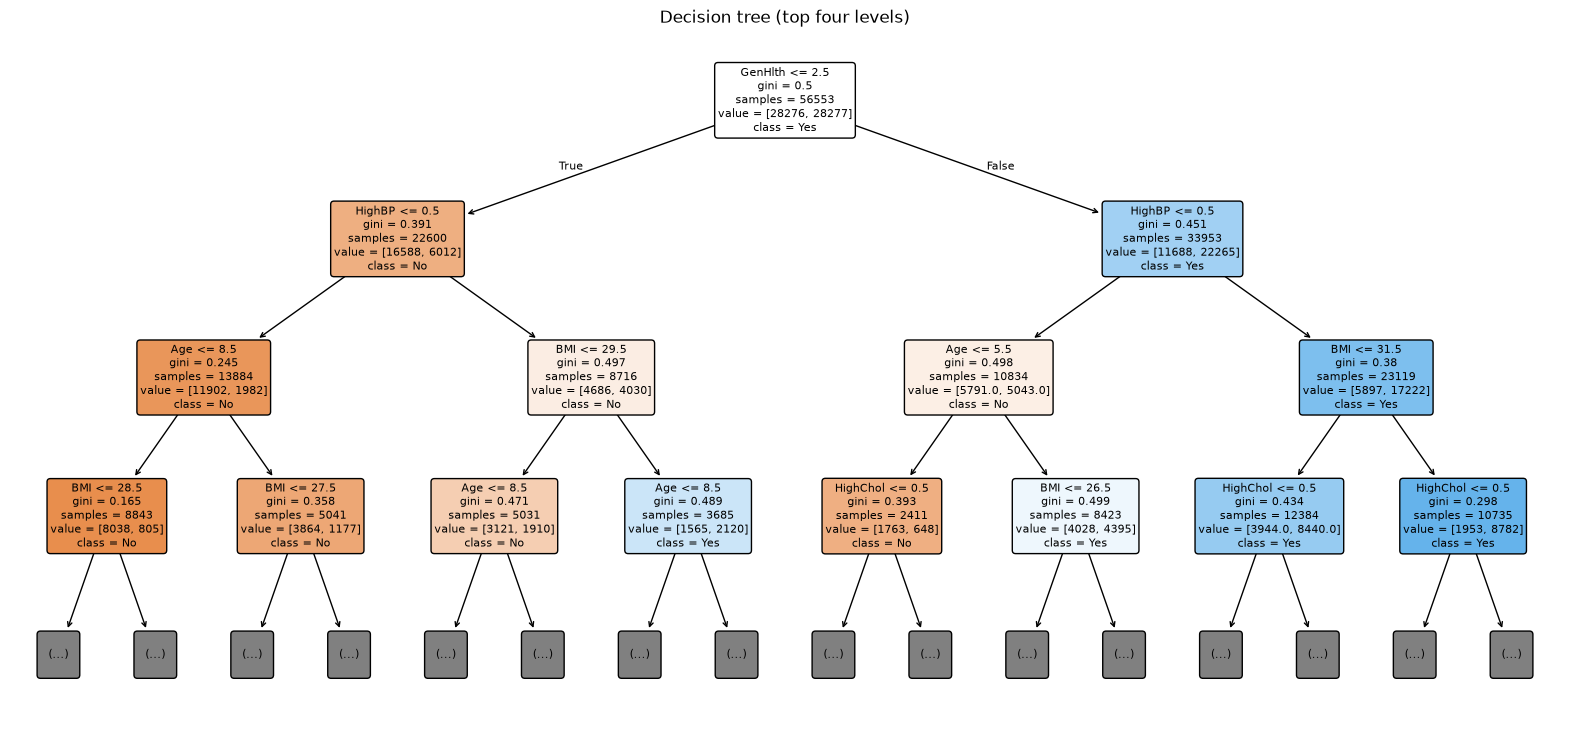

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree

model = make_pipeline(SimpleImputer(strategy='median'),
                      DecisionTreeClassifier(max_depth=4, min_samples_leaf=100,
                                             random_state=SEED))
model.fit(X_train, y_train)
probabilities = model.predict_proba(X_test)[:, 1]
plt.figure(figsize=(20, 9))
plot_tree(model[-1], feature_names=features, class_names=['No', 'Yes'],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Decision tree (top four levels)'); plt.show()


## Held-out evaluation

                  precision    recall  f1-score   support

no (pre)diabetes       0.75      0.68      0.71      7070
   (pre)diabetes       0.71      0.78      0.74      7069

        accuracy                           0.73     14139
       macro avg       0.73      0.73      0.73     14139
    weighted avg       0.73      0.73      0.73     14139

ROC AUC: 0.795
Average precision: 0.752
Brier score (balanced sample only): 0.182


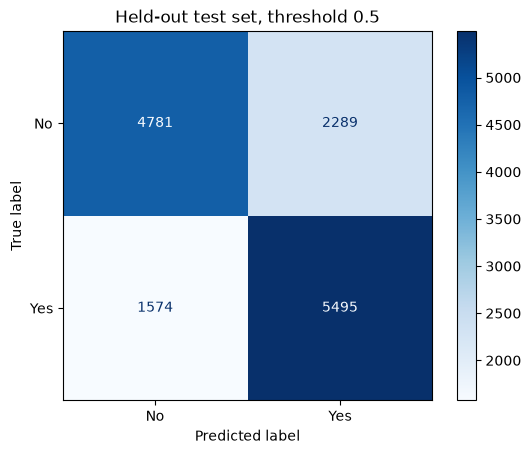

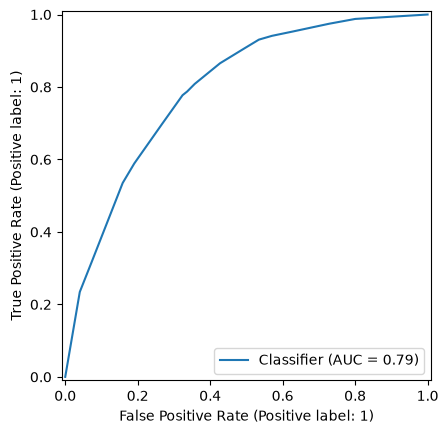

In [5]:
def evaluate(y_true, probability, threshold=0.5):
    prediction = (probability >= threshold).astype(int)
    print(classification_report(y_true, prediction, target_names=['no (pre)diabetes', '(pre)diabetes']))
    print(f'ROC AUC: {roc_auc_score(y_true, probability):.3f}')
    print(f'Average precision: {average_precision_score(y_true, probability):.3f}')
    print(f'Brier score (balanced sample only): {brier_score_loss(y_true, probability):.3f}')
    ConfusionMatrixDisplay.from_predictions(y_true, prediction, display_labels=['No', 'Yes'], cmap='Blues')
    plt.title('Held-out test set, threshold 0.5'); plt.show()
    RocCurveDisplay.from_predictions(y_true, probability); plt.show()

evaluate(y_test, probabilities)


## Local explanation: exact decision path

The conditions below show why the tree assigned its leaf score. They do not estimate the effect of changing a feature.

In [12]:
row = explain_row.copy()
print("Decision-path respondent index:", EXPLAIN_INDEX)
filled = model[0].transform(row)
tree_model = model[-1]
node_ids = tree_model.decision_path(filled).indices
for node in node_ids:
    feature_index = tree_model.tree_.feature[node]
    if feature_index < 0:
        break
    value = filled[0, feature_index]
    limit = tree_model.tree_.threshold[node]
    relation = '<=' if value <= limit else '>'
    print(f'{features[feature_index]} = {value:g} {relation} {limit:.3g}')
print('Model score:', round(model.predict_proba(row)[0, 1], 3))
print('True survey label:', int(y_test.iloc[row_position]))


Decision-path respondent index: 57608
GenHlth = 4 > 2.5
HighBP = 1 > 0.5
BMI = 53 > 31.5
HighChol = 1 > 0.5
Model score: 0.853
True survey label: 1


## Error audit

Review false negatives and false positives. Features such as `Age`, `Income`, and access to care may encode social patterns; differences in this dataset alone cannot establish fairness or clinical safety.

In [13]:
audit = X_test.copy()
audit['actual'] = y_test
audit['score'] = probabilities
audit['predicted'] = (probabilities >= 0.5).astype(int)
display(audit.loc[(audit.actual == 1) & (audit.predicted == 0)].sort_values('score').head(10))
display(audit.loc[(audit.actual == 0) & (audit.predicted == 1)].sort_values('score', ascending=False).head(10))


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,actual,score,predicted
67337,0.0,0.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,2.0,0.0,1.0,7.0,5.0,8.0,1,0.058439,0
64216,0.0,1.0,1.0,28.0,0.0,0.0,0.0,1.0,0.0,1.0,...,5.0,1.0,0.0,0.0,5.0,6.0,7.0,1,0.058439,0
52613,0.0,1.0,1.0,21.0,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,7.0,5.0,8.0,1,0.058439,0
50636,0.0,1.0,1.0,24.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,1.0,8.0,6.0,8.0,1,0.058439,0
36898,0.0,0.0,1.0,28.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,6.0,4.0,6.0,1,0.058439,0
40011,0.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,3.0,0.0,1.0,5.0,4.0,6.0,1,0.058439,0
55875,0.0,1.0,1.0,28.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,5.0,6.0,8.0,1,0.058439,0
38057,0.0,1.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,4.0,6.0,8.0,1,0.058439,0
69246,0.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,0.0,0.0,...,8.0,0.0,0.0,0.0,7.0,5.0,8.0,1,0.058439,0
36475,0.0,0.0,1.0,20.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,7.0,6.0,8.0,1,0.058439,0


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,actual,score,predicted
30163,1.0,1.0,1.0,34.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,4.0,1.0,0.0,10.0,4.0,5.0,0,0.852626,1
15553,1.0,1.0,1.0,36.0,1.0,0.0,0.0,1.0,1.0,1.0,...,30.0,14.0,1.0,0.0,4.0,5.0,1.0,0,0.852626,1
12226,1.0,1.0,1.0,32.0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,13.0,3.0,2.0,0,0.852626,1
3586,1.0,1.0,1.0,32.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,15.0,0.0,1.0,7.0,2.0,3.0,0,0.852626,1
4134,1.0,1.0,1.0,35.0,1.0,0.0,0.0,1.0,1.0,1.0,...,2.0,2.0,1.0,0.0,9.0,5.0,4.0,0,0.852626,1
26147,1.0,1.0,1.0,34.0,1.0,0.0,0.0,0.0,0.0,1.0,...,11.0,5.0,1.0,0.0,10.0,5.0,3.0,0,0.852626,1
12839,1.0,1.0,1.0,32.0,1.0,0.0,0.0,0.0,0.0,0.0,...,3.0,15.0,1.0,0.0,7.0,4.0,6.0,0,0.852626,1
32602,1.0,1.0,1.0,36.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,2.0,0.0,1.0,8.0,4.0,8.0,0,0.852626,1
6838,1.0,1.0,1.0,33.0,0.0,0.0,1.0,1.0,1.0,1.0,...,5.0,15.0,1.0,0.0,12.0,5.0,5.0,0,0.852626,1
17028,1.0,1.0,1.0,35.0,0.0,0.0,0.0,0.0,1.0,0.0,...,25.0,20.0,1.0,1.0,8.0,5.0,3.0,0,0.852626,1


## Local LIME explanation — shared reference person
Requires `lime` and `shap` in your Python environment.

LIME respondent index: 57608
Modelscore for (præ)diabetes: 0.853
[('HighBP=1', 0.22821365089084356), ('3.00 < GenHlth <= 4.00', 0.14263584347646752), ('BMI > 33.00', 0.1145499569251902), ('HighChol=1', 0.06218954918018462), ('9.00 < Age <= 11.00', 0.05270837343831154), ('HvyAlcoholConsump=0', -0.029015532207846074), ('CholCheck=1', -0.02348431191720522), ('AnyHealthcare=1', -0.012720335439911563), ('Sex=0', 0.011910722445191542), ('HeartDiseaseorAttack=0', -0.011231132100800468)]


c:\Users\vict7\miniforge3\envs\forklarbar-fixed\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


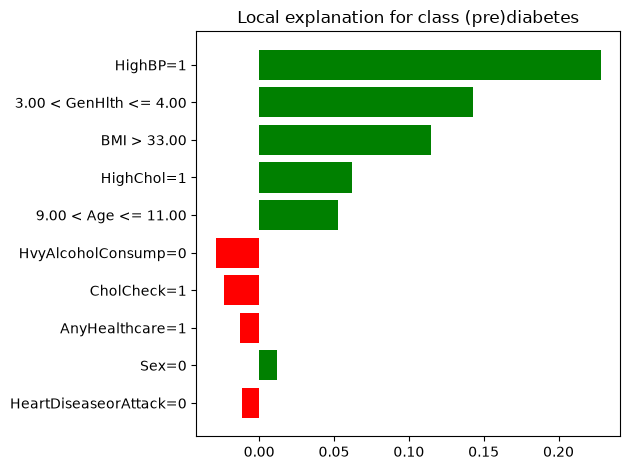

In [14]:
from lime.lime_tabular import LimeTabularExplainer

# Fortæl LIME, hvilke inputvariabler der kun har værdierne 0 og 1
categorical_features = [
    i for i, feature in enumerate(features)
    if X_train[feature].nunique(dropna=True) <= 2
]

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(dtype=float),
    feature_names=features,
    class_names=["No (pre)diabetes", "(pre)diabetes"],
    categorical_features=categorical_features,
    mode="classification",
    random_state=SEED
)

# Vælg én person fra testdata
row = explain_row.iloc[0]
print("LIME respondent index:", EXPLAIN_INDEX)

lime_explanation = lime_explainer.explain_instance(
    data_row=row.to_numpy(dtype=float),
    predict_fn=lambda values: model.predict_proba(
        pd.DataFrame(values, columns=features)),
    labels=(1,),
    num_features=10,
    num_samples=3000
)

# Vis hvilke variabler der påvirker forklaringen for klasse 1
print("Modelscore for (præ)diabetes:",
      round(model.predict_proba(row.to_frame().T)[0, 1], 3))
print(lime_explanation.as_list(label=1))

lime_explanation.as_pyplot_figure(label=1)
plt.tight_layout()
plt.show()

In [15]:
print("LIME local fidelity:", lime_explanation.score)

LIME local fidelity: 0.45032224021242817


## Kernel SHAP — global sample and shared local reference person
The same settings as the neural-network notebook are used: 50 background rows, 40 global test rows, and 200 coalition samples per person.

In [ ]:
import shap

# Et lille udsnit af træningsdata bruges som sammenligningsgrundlag
background = X_train.sample(
    n=min(50, len(X_train)),
    random_state=SEED
)

# Forklar op til 40 testpersoner
X_shap = X_test.sample(
    n=min(40, len(X_test)),
    random_state=SEED
)

# Bevar de korrekte feature-navne og deres rækkefølge
def predict_for_shap(values):
    frame = pd.DataFrame(
        np.asarray(values),
        columns=features
    )
    return model.predict_proba(frame)


shap_explainer = shap.KernelExplainer(
    predict_for_shap,
    background
)

# Seed coalition sampling independently of earlier cells.
np.random.seed(SEED)
shap_values = shap_explainer.shap_values(
    X_shap,
    nsamples=200
)

# Udtræk SHAP-værdier for klasse 1: (præ)diabetes
# SHAP-versioner kan returnere værdierne i lidt forskellige formater.
if isinstance(shap_values, list):
    shap_positive = shap_values[1]
else:
    shap_values = np.asarray(shap_values)
    shap_positive = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values

# Samlet oversigt: hvilke variabler betyder mest på tværs af personerne?
shap.summary_plot(
    shap_positive,
    X_shap,
    feature_names=features,
    plot_type="bar"
)

100%|██████████| 1/1 [00:00<00:00, 63.80it/s]


SHAP respondent index: 57608
Model score: 0.8526260087313137
True survey label: 1
SHAP base + contributions: 0.8526260087313136


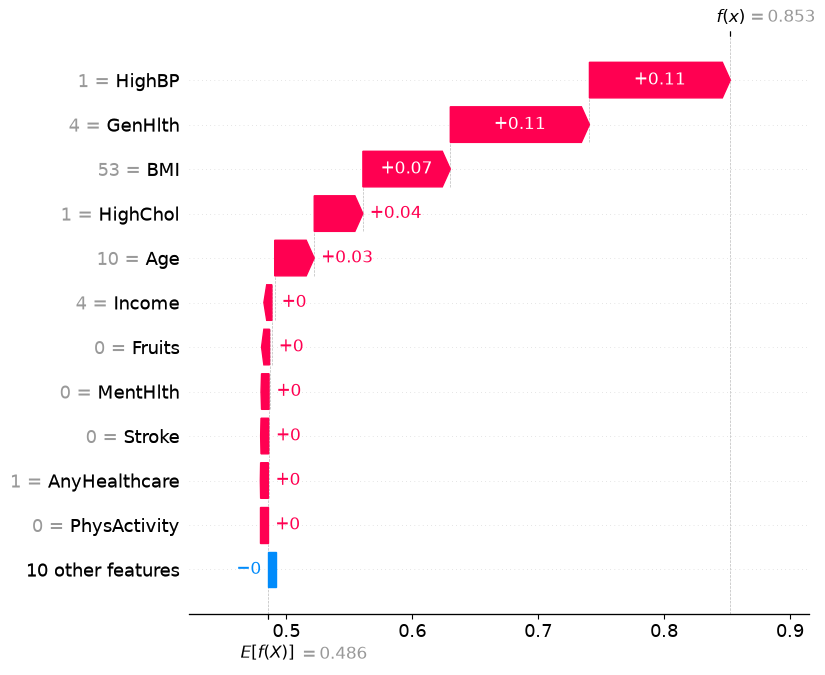

,Feature,Raw value,SHAP contribution (class 1)
0,HighBP,1.0,0.111928
1,HighChol,1.0,0.038655
2,CholCheck,1.0,0.000000
3,BMI,53.0,0.069431
4,Smoker,0.0,0.000000
5,Stroke,0.0,0.000311
6,HeartDiseaseorAttack,0.0,0.000000
7,PhysActivity,0.0,0.000000
8,Fruits,0.0,0.001852
9,Veggies,1.0,0.000000


In [18]:
# Explain the selected person separately from the global random sample.
# This keeps the global summary based on its original random 40-person sample.
np.random.seed(SEED)
selected_shap_values = shap_explainer.shap_values(explain_row, nsamples=200)
if isinstance(selected_shap_values, list):
    selected_positive = np.asarray(selected_shap_values[1])[0]
else:
    selected_array = np.asarray(selected_shap_values)
    selected_positive = (selected_array[0, :, 1]
                         if selected_array.ndim == 3 else selected_array[0])

expected = np.asarray(shap_explainer.expected_value).reshape(-1)
base_value = float(expected[1] if len(expected) > 1 else expected[0])
local_shap = shap.Explanation(
    values=selected_positive,
    base_values=base_value,
    data=explain_row.iloc[0].to_numpy(),
    feature_names=features
)
print("SHAP respondent index:", EXPLAIN_INDEX)
print("Model score:", float(model.predict_proba(explain_row)[0, 1]))
print("True survey label:", int(y_test.loc[EXPLAIN_INDEX]))
print("SHAP base + contributions:", base_value + selected_positive.sum())
shap.plots.waterfall(local_shap, max_display=12)
display(pd.DataFrame({
    "Feature": features,
    "Raw value": explain_row.iloc[0].to_numpy(),
    "SHAP contribution (class 1)": selected_positive
}))


## Export reproducible evidence

These files contain the results of the current run, not hard-coded report values. Test predictions include original row indices so comparisons can be paired correctly. Runtime versions and the dataset hash are recorded alongside the outputs. Run both notebooks before comparing predictions.


In [ ]:
import hashlib
import json
import platform
from importlib.metadata import version

output_dir = Path("results/dt")
output_dir.mkdir(parents=True, exist_ok=True)
pd.DataFrame({
    "dataset_index": X_test.index,
    "actual": y_test.to_numpy(),
    "score": probabilities,
    "predicted": (probabilities >= 0.5).astype(int),
}).to_csv(output_dir / "test_predictions.csv", index=False)
explain_row.to_csv(output_dir / "patient_raw.csv", index_label="dataset_index")
pd.DataFrame({"feature": features, "mean_abs_shap": np.abs(shap_positive).mean(axis=0)}).sort_values(
    "mean_abs_shap", ascending=False
).to_csv(output_dir / "global_shap.csv", index=False)
pd.DataFrame({"feature": features, "raw_value": explain_row.iloc[0].to_numpy(),
              "shap_contribution": selected_positive}).to_csv(output_dir / "patient_shap.csv", index=False)
pd.DataFrame(lime_explanation.as_list(label=1), columns=["condition", "weight"]).to_csv(
    output_dir / "patient_lime.csv", index=False)
metadata = {
    "model": "dt", "seed": SEED, "patient_index": EXPLAIN_INDEX,
    "dataset_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "python": platform.python_version(),
    "versions": {package: version(package) for package in
                 ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "lime", "shap"]},
    "accuracy": float(np.mean((probabilities >= 0.5) == y_test.to_numpy())),
    "roc_auc": float(roc_auc_score(y_test, probabilities)),
    "patient_score": float(model.predict_proba(explain_row)[0, 1]),
    "lime_weighted_r2": float(lime_explanation.score),
    "shap_baseline": base_value,
    "shap_reconstruction_error": float(abs(base_value + selected_positive.sum()
                                          - model.predict_proba(explain_row)[0, 1])),
}
(output_dir / "run_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved current-run evidence to", output_dir.resolve())
